# 03c - Class imbalance: softer class weights and probability scaling
Goal: reduce the Bot / DDoS / Prob confusion found in `03b_strong_models.ipynb` and raise multi-class macro F1.

In 03b, `class_weight="balanced"` raised Bot recall from 5% to 87% but its precision fell to 0.19, so macro F1 dropped (0.647 → 0.615). `balanced` is all or nothing. Here we test two softer options:

1. **Softer class weights (LightGBM):** weight = `balanced_weight ** alpha`. `alpha = 0` is no weighting, `alpha = 1` is `balanced`, values in between are a compromise.
2. **Probability scaling (LightGBM and Random Forest):** after training, multiply the predicted probability of each class by a factor and take the largest. This moves the decision border between classes without retraining.

Both are chosen on a **validation set** cut from the training set. The test set is used only once, for the final numbers.

## 1. Setup

In [1]:
import sys
sys.path.append('..')

import time
import joblib
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight

from src.config import RANDOM_STATE, FEATURE_COLS

train = pd.read_parquet('../data/processed/train.parquet')
test = pd.read_parquet('../data/processed/test.parquet')

X_train, y_train = train[FEATURE_COLS], train['label_multi']
X_test, y_test = test[FEATURE_COLS], test['label_multi']
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (341633, 62) | Test: (85409, 62)


### Validation set
20% of the training set (stratified) is kept aside to choose `alpha` and the scaling factors. Models in sections 2–4 are trained on the other 80% (`fit`).

In [2]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE
)
print('Fit:', X_fit.shape, '| Validation:', X_val.shape)
print(y_val.value_counts())

Fit: (273306, 62) | Validation: (68327, 62)
label_multi
Benign    37400
Dos       20241
DDoS       8043
Bot        1433
Prob       1210
Name: count, dtype: int64


## 2. Softer class weights (LightGBM)
The tuned LightGBM parameters from 03b are used. For each `alpha`, every training row gets the weight of its class, `balanced_weight ** alpha`, through `sample_weight`.

In [3]:
LGBM_PARAMS = dict(subsample=0.6, num_leaves=63, n_estimators=500, min_child_samples=50,
                   max_depth=10, learning_rate=0.1, colsample_bytree=0.8, subsample_freq=1,
                   random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)

classes = np.unique(y_train)
balanced = pd.Series(compute_class_weight('balanced', classes=classes, y=y_fit), index=classes)

def class_weights(alpha):
    return balanced ** alpha

pd.DataFrame({a: class_weights(a) for a in [0, 0.25, 0.5, 0.75, 1]}).round(2)

,0.00,0.25,0.50,0.75,1.00
Benign,1.0,0.78,0.60,0.47,0.37
Bot,1.0,1.76,3.09,5.43,9.54
DDoS,1.0,1.14,1.30,1.49,1.70
Dos,1.0,0.91,0.82,0.74,0.68
Prob,1.0,1.83,3.36,6.16,11.29


In [4]:
ALPHAS = [0, 0.25, 0.5, 0.75, 1]
val_proba = {}   # alpha -> predicted probabilities on the validation set
rows = []

for alpha in ALPHAS:
    model = LGBMClassifier(**LGBM_PARAMS)
    t0 = time.perf_counter()
    model.fit(X_fit, y_fit, sample_weight=y_fit.map(class_weights(alpha)))
    fit_time = time.perf_counter() - t0

    proba = model.predict_proba(X_val)
    val_proba[alpha] = proba
    pred = model.classes_[proba.argmax(axis=1)]
    rows.append({'alpha': alpha,
                 'val_macro_f1': f1_score(y_val, pred, average='macro'),
                 'val_accuracy': accuracy_score(y_val, pred),
                 'fit_time_s': round(fit_time, 1)})

assert list(model.classes_) == list(classes)
alpha_table = pd.DataFrame(rows).set_index('alpha')
alpha_table.round(4)

,val_macro_f1,val_accuracy,fit_time_s
alpha,,,
0.00,0.6590,0.8785,31.2
0.25,0.6791,0.8769,28.1
0.50,0.6803,0.8689,43.9
0.75,0.6605,0.8545,41.4
1.00,0.6278,0.8371,42.5


## 3. Probability scaling
`scale_predict` multiplies each class column of the probabilities by a factor and takes the largest. `fit_factors` searches the factors one class at a time (Benign stays at 1, because only the ratios matter) over a grid from 0.2 to 5, keeps the value with the best validation macro F1, and repeats the pass three times.

In [5]:
GRID = np.geomspace(0.2, 5, 25)

def scale_predict(proba, factors):
    return classes[(proba * factors).argmax(axis=1)]

def fit_factors(proba, y_true, n_rounds=3):
    factors = np.ones(len(classes))
    best = f1_score(y_true, scale_predict(proba, factors), average='macro')
    for _ in range(n_rounds):
        for j in range(1, len(classes)):          # class 0 (Benign) stays at 1
            for f in GRID:
                trial = factors.copy()
                trial[j] = f
                score = f1_score(y_true, scale_predict(proba, trial), average='macro')
                if score > best:
                    best, factors = score, trial
    return factors, best

In [6]:
scaled = {}
for alpha in ALPHAS:
    factors, score = fit_factors(val_proba[alpha], y_val)
    scaled[alpha] = factors
    alpha_table.loc[alpha, 'val_macro_f1_scaled'] = score

alpha_table.round(4)

,val_macro_f1,val_accuracy,fit_time_s,val_macro_f1_scaled
alpha,,,,
0.00,0.6590,0.8785,31.2,0.6895
0.25,0.6791,0.8769,28.1,0.6908
0.50,0.6803,0.8689,43.9,0.6910
0.75,0.6605,0.8545,41.4,0.6884
1.00,0.6278,0.8371,42.5,0.6836


In [7]:
best_alpha = alpha_table['val_macro_f1_scaled'].idxmax()
lgbm_factors = scaled[best_alpha]
print('Best alpha:', best_alpha)
print('Scaling factors:', {c: round(float(f), 3) for c, f in zip(classes, lgbm_factors)})

Best alpha: 0.5
Scaling factors: {'Benign': 1.0, 'Bot': 1.144, 'DDoS': 1.144, 'Dos': 1.144, 'Prob': 0.511}


## 4. Random Forest with probability scaling
The tuned Random Forest from 03b (the saved best model) is trained the same way on the `fit` part, and the factors are searched on its validation probabilities. Softer class weights are not tried here: in 03b, `balanced` had almost no effect on Random Forest.

In [8]:
RF_PARAMS = dict(n_estimators=300, min_samples_leaf=2, max_features=0.3, max_depth=30,
                 random_state=RANDOM_STATE, n_jobs=-1)

rf_fit = RandomForestClassifier(**RF_PARAMS).fit(X_fit, y_fit)
rf_val_proba = rf_fit.predict_proba(X_val)
rf_val_base = f1_score(y_val, classes[rf_val_proba.argmax(axis=1)], average='macro')

rf_factors, rf_val_scaled = fit_factors(rf_val_proba, y_val)
print(f'Validation macro F1: {rf_val_base:.4f} -> {rf_val_scaled:.4f} with scaling')
print('Scaling factors:', {c: round(float(f), 3) for c, f in zip(classes, rf_factors)})
del rf_fit

Validation macro F1: 0.6732 -> 0.6843 with scaling
Scaling factors: {'Benign': 1.0, 'Bot': 2.236, 'DDoS': 1.308, 'Dos': 0.669, 'Prob': 1.0}


## 5. Final test
The chosen settings are now measured once on the test set:

- **LightGBM:** retrained on the full training set with `best_alpha`, then the validation factors are applied.
- **Random Forest:** `models/best_model.joblib` from 03b (already trained on the full training set), with the validation factors applied.

Baselines are the same models without scaling. Prediction time includes `predict_proba` and the scaling.

In [9]:
def test_row(name, proba_fn, factors, imbalance, notes, train_time=np.nan):
    t0 = time.perf_counter()
    proba = proba_fn(X_test)
    pred = scale_predict(proba, factors)
    ms = (time.perf_counter() - t0) / len(X_test) * 1000
    return pred, {'model': name, 'task': 'multi', 'imbalance': imbalance,
                  'macro_f1': f1_score(y_test, pred, average='macro'),
                  'accuracy': accuracy_score(y_test, pred),
                  'train_time_s': round(train_time, 2), 'predict_ms_per_flow': round(ms, 5),
                  'notes': notes}

ones = np.ones(len(classes))
results, preds = [], {}

# LightGBM, full training set
lgbm = LGBMClassifier(**LGBM_PARAMS)
t0 = time.perf_counter()
lgbm.fit(X_train, y_train, sample_weight=y_train.map(class_weights(best_alpha)))
lgbm_time = time.perf_counter() - t0

imb = 'none' if best_alpha == 0 else f'weight_alpha={best_alpha}'
factor_note = 'scaling ' + str({c: round(float(f), 3) for c, f in zip(classes, lgbm_factors)})
for key, f, note in [('LightGBM', ones, 'tuned'), ('LightGBM + scaling', lgbm_factors, f'tuned, {factor_note}')]:
    preds[key], row = test_row('LightGBM', lgbm.predict_proba, f, imb, note, lgbm_time)
    results.append(row)

# Random Forest, saved best model
rf = joblib.load('../models/best_model.joblib')
assert list(rf.classes_) == list(classes)
rf_note = 'scaling ' + str({c: round(float(f), 3) for c, f in zip(classes, rf_factors)})
for key, f, note in [('RandomForest', ones, 'tuned (best_model.joblib)'),
                     ('RandomForest + scaling', rf_factors, f'tuned (best_model.joblib), {rf_note}')]:
    preds[key], row = test_row('RandomForest', rf.predict_proba, f, 'none', note)
    results.append(row)

final = pd.DataFrame(results)
final.index = list(preds)
final[['macro_f1', 'accuracy', 'predict_ms_per_flow']].round(4)

,macro_f1,accuracy,predict_ms_per_flow
LightGBM,0.6845,0.8711,0.0419
LightGBM + scaling,0.6869,0.8710,0.0504
RandomForest,0.6734,0.8719,0.0121
RandomForest + scaling,0.6828,0.8703,0.0122


## 6. Per-class results

In [10]:
from sklearn.metrics import precision_recall_fscore_support

def per_class(pred):
    p, r, f, _ = precision_recall_fscore_support(y_test, pred, labels=classes, zero_division=0)
    return pd.DataFrame({'precision': p, 'recall': r, 'f1': f}, index=classes)

per_class_table = pd.concat({k: per_class(v) for k, v in preds.items()}, axis=0)
per_class_table.round(3)

precision  recall     f1
LightGBM               Benign      0.978   0.897  0.936
                       Bot         0.277   0.441  0.340
                       DDoS        0.554   0.787  0.651
                       Dos         0.962   0.904  0.932
                       Prob        0.548   0.580  0.564
LightGBM + scaling     Benign      0.979   0.896  0.935
                       Bot         0.275   0.443  0.339
                       DDoS        0.548   0.800  0.650
                       Dos         0.957   0.906  0.931
                       Prob        0.685   0.501  0.579
RandomForest           Benign      0.932   0.924  0.928
                       Bot         0.347   0.237  0.282
                       DDoS        0.579   0.704  0.635
                       Dos         0.936   0.910  0.923
                       Prob        0.722   0.512  0.599
RandomForest + scaling Benign      0.940   0.920  0.930
                       Bot         0.282   0.369  0.320
                       DDoS        0.564   0.719  0.632
                       Dos         0.964   0.897  0.930
                       Prob        0.763   0.499  0.603

In [11]:
best_key = final['macro_f1'].idxmax()
print('Best on test:', best_key)
print(classification_report(y_test, preds[best_key], digits=4))

Best on test: LightGBM + scaling


              precision    recall  f1-score   support

      Benign     0.9789    0.8956    0.9354     46749
         Bot     0.2746    0.4431    0.3391      1792
        DDoS     0.5477    0.8000    0.6502     10054
         Dos     0.9573    0.9063    0.9311     25301
        Prob     0.6847    0.5010    0.5786      1513

    accuracy                         0.8710     85409
   macro avg     0.6886    0.7092    0.6869     85409
weighted avg     0.9017    0.8710    0.8817     85409



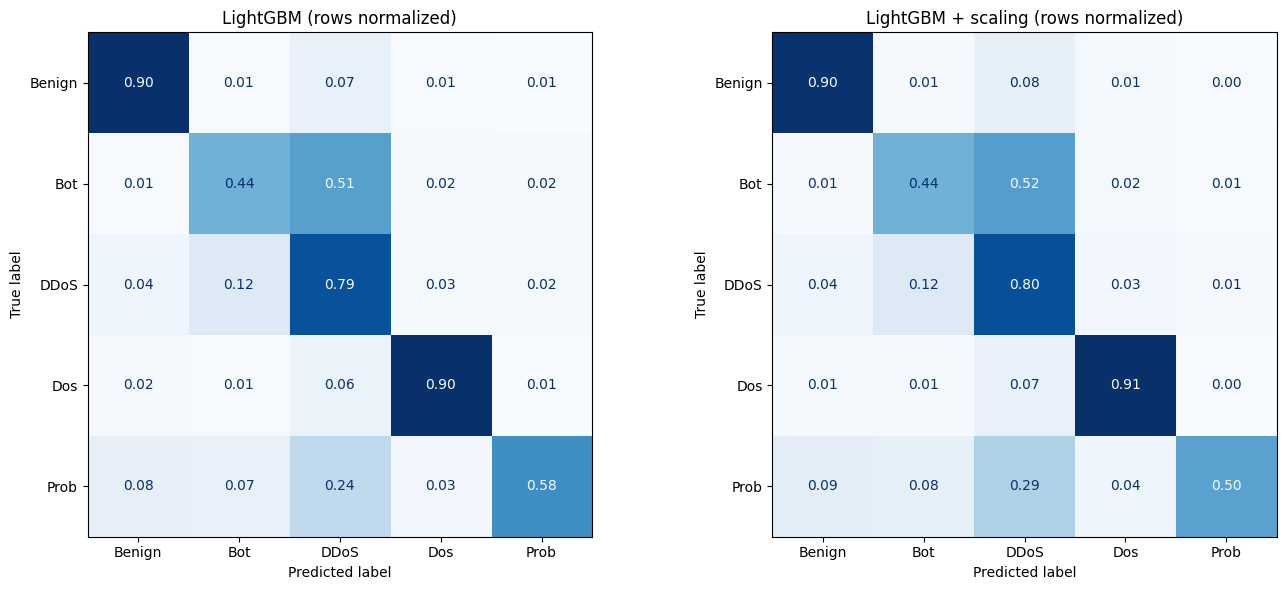

In [12]:
import os
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

FIG_DIR = '../reports/figures'
os.makedirs(FIG_DIR, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, key in zip(axes, [best_key.replace(' + scaling', ''), best_key]):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[key], normalize='true', values_format='.2f',
                                            cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(f'{key} (rows normalized)')
fig.tight_layout()
fig.savefig(f'{FIG_DIR}/cm_scaling_comparison.png', dpi=150)
plt.show()

## 7. Results

In [13]:
COLS = ['model', 'task', 'imbalance', 'macro_f1', 'accuracy', 'train_time_s', 'predict_ms_per_flow', 'notes']
final[COLS].to_csv('../reports/results_imbalance.csv', index=False)
final[COLS]

,model,task,imbalance,macro_f1,accuracy,train_time_s,predict_ms_per_flow,notes
LightGBM,LightGBM,multi,weight_alpha=0.5,0.684517,0.871138,40.5,0.04194,tuned
LightGBM + scaling,LightGBM,multi,weight_alpha=0.5,0.686879,0.871021,40.5,0.05038,"tuned, scaling {'Benign': 1.0, 'Bot': 1.144, '..."
RandomForest,RandomForest,multi,none,0.673362,0.871922,NaN,0.01213,tuned (best_model.joblib)
RandomForest + scaling,RandomForest,multi,none,0.682837,0.870260,NaN,0.01218,"tuned (best_model.joblib), scaling {'Benign': ..."



## 8. Summary

| Model (multi-class, test set) | Macro F1 | Accuracy | Bot F1 |
|---|---|---|---|
| Random Forest, tuned (03b best model) | 0.673 | 0.872 | 0.28 |
| Random Forest + scaling | 0.683 | 0.870 | 0.32 |
| LightGBM, tuned, weights `alpha=0.5` | 0.685 | 0.871 | 0.34 |
| **LightGBM, tuned, weights `alpha=0.5` + scaling** | **0.687** | 0.871 | 0.34 |

- **Softer class weights work, full `balanced` does not.** On the validation set, `alpha` 0.25–0.5 raised LightGBM macro F1 from 0.659 to about 0.68, while `alpha=1` (`balanced`) lowered it to 0.628, as in 03b. A small push towards the rare classes helps, a full push costs too much precision.
- **Probability scaling adds about +0.01** on validation for every `alpha` and for Random Forest, without retraining. The factors mainly raise Bot and lower Prob/Dos.
- **On the test set** the best setting (LightGBM, `alpha=0.5`, scaling) reaches macro F1 **0.687**, +0.014 over the 03b best model (0.673). Bot recall goes from 0.24 to 0.44 (F1 0.28 → 0.34); accuracy stays about the same.
- **Bot is still the weakest class.** Most of the gain comes from moving the Bot/DDoS border; the two classes still overlap in the 62 features.
- **Run-to-run variation:** with `n_jobs=-1`, LightGBM is not bit-identical between runs. `alpha=0.25` and `alpha=0.5` differ by only 0.0002 on validation; an earlier run of this notebook picked `alpha=0.25` and got 0.690 on the test set. The gain over the 03b best model appeared in both runs.
- **Not changed here:** `models/best_model.joblib` is still the tuned Random Forest. Switching the demo to LightGBM + scaling would need the scaling factors saved next to the model and applied before taking the largest probability. This is left to a team decision.
